<a href="https://colab.research.google.com/github/janarthmanoharan7/Emotion-Aware-AI-Live-Demo/blob/main/Emotion_Aware_AI_Live_Demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install openai-whisper
!pip install librosa
!pip install soundfile
!pip install matplotlib
!pip install pandas
!pip install ipywidgets

In [ ]:
!pip install transformers
!pip install torchaudio

In [ ]:
!pip install transformers torchaudio

In [ ]:
import whisper
import librosa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, Audio, Javascript
from google.colab import files
from google.colab.output import eval_js
from base64 import b64decode

In [ ]:
from transformers import pipeline
import torch

emotion_classifier = pipeline(
    task="audio-classification",
    model="ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition",
    device=0 if torch.cuda.is_available() else -1
)

print("✅ Emotion Model Loaded Successfully")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition
Key                      | Status     | 
-------------------------+------------+-
classifier.output.bias   | UNEXPECTED | 
classifier.dense.weight  | UNEXPECTED | 
classifier.dense.bias    | UNEXPECTED | 
classifier.output.weight | UNEXPECTED | 
projector.weight         | MISSING    | 
classifier.bias          | MISSING    | 
projector.bias           | MISSING    | 
classifier.weight        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Emotion Model Loaded Successfully


In [ ]:
model = whisper.load_model("base")
print("✅ Whisper Model Loaded Successfully")

✅ Whisper Model Loaded Successfully


In [ ]:
from transformers import pipeline

emotion_classifier = pipeline(
    task="audio-classification",
    model="ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition"
)

print("✅ Advanced Emotion Model Loaded")

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition
Key                      | Status     | 
-------------------------+------------+-
classifier.output.bias   | UNEXPECTED | 
classifier.dense.weight  | UNEXPECTED | 
classifier.dense.bias    | UNEXPECTED | 
classifier.output.weight | UNEXPECTED | 
projector.weight         | MISSING    | 
classifier.bias          | MISSING    | 
projector.bias           | MISSING    | 
classifier.weight        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Advanced Emotion Model Loaded


In [ ]:
import librosa
import numpy as np
import soundfile as sf

def detect_emotion(audio_path):
    # Load and resample to 16kHz
    y, sr = librosa.load(audio_path, sr=16000)

    # Normalize audio (important for stability)
    if np.max(np.abs(y)) > 0:
        y = y / np.max(np.abs(y))

    # Save normalized temp file
    temp_path = "normalized_audio.wav"
    sf.write(temp_path, y, 16000)

    # Run emotion model
    results = emotion_classifier(temp_path)

    # Sort by confidence
    results = sorted(results, key=lambda x: x['score'], reverse=True)

    return results[:3]

In [ ]:
def transcribe_audio(audio_path):
    result = model.transcribe(audio_path)

    detected_language = result["language"]
    transcript = result["text"]

    # Supported languages (you can expand this list)
    supported_languages = [
        "en",  # English
        "ta",  # Tamil
        "hi",  # Hindi
        "te",  # Telugu
        "ml",  # Malayalam
        "kn"   # Kannada
    ]

    if detected_language in supported_languages:
        return detected_language, transcript
    else:
        return detected_language, "⚠ Transcript not available for this language."

In [ ]:
def record_audio(filename='recorded_audio.wav'):
    display(Javascript("""
    window.recordedChunks = [];
    window.mediaRecorder = null;

    async function startRecording() {
        const stream = await navigator.mediaDevices.getUserMedia({ audio: true });
        window.mediaRecorder = new MediaRecorder(stream);
        window.recordedChunks = [];

        window.mediaRecorder.ondataavailable = function(e) {
            window.recordedChunks.push(e.data);
        };

        window.mediaRecorder.start();
    }

    async function stopRecording() {
        return new Promise(resolve => {
            window.mediaRecorder.onstop = async () => {
                const blob = new Blob(window.recordedChunks);
                const arrayBuffer = await blob.arrayBuffer();
                const base64String = btoa(
                    new Uint8Array(arrayBuffer)
                        .reduce((data, byte) => data + String.fromCharCode(byte), '')
                );
                resolve(base64String);
            };
            window.mediaRecorder.stop();
        });
    }
    """))

    print("🎤 Starting Recording...")
    display(Javascript("startRecording()"))

    input("Press ENTER to STOP recording...")

    audio_base64 = eval_js("stopRecording()")
    audio_bytes = b64decode(audio_base64)

    with open(filename, 'wb') as f:
        f.write(audio_bytes)

    print("✅ Recording Saved")

    return filename

In [ ]:
option = widgets.RadioButtons(
    options=['Upload Audio', 'Record Audio'],
    description='Choose Input:',
)

display(option)

NameError: name 'widgets' is not defined

In [ ]:
if option.value == 'Upload Audio':
    uploaded = files.upload()
    audio_path = list(uploaded.keys())[0]

elif option.value == 'Record Audio':
    audio_path = record_audio()

print("✅ Audio Ready:", audio_path)
Audio(audio_path)

<IPython.core.display.Javascript object>

🎤 Starting Recording...


<IPython.core.display.Javascript object>

✅ Recording Saved
✅ Audio Ready: recorded_audio.wav


/tmp/ipython-input-2511117248.py:7: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(audio_path, sr=16000)
/usr/local/lib/python3.12/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)



🎭 Emotion Predictions:

surprised : 13.38%
sad : 13.29%
happy : 12.98%


/usr/local/lib/python3.12/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")



🌍 Detected Language: ja

📝 Transcript:
⚠ Transcript not available for this language.


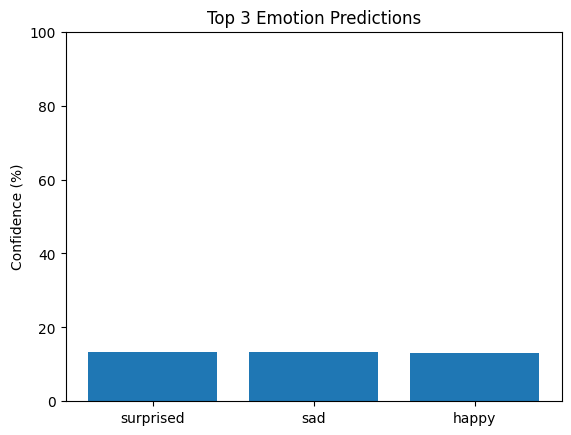

In [ ]:
# Emotion Detection
top_emotions = detect_emotion(audio_path)

print("\n🎭 Emotion Predictions:\n")

for item in top_emotions:
    print(f"{item['label']} : {round(item['score'] * 100, 2)}%")

# Take highest emotion for further use
emotion = top_emotions[0]['label']
confidence = top_emotions[0]['score']

# Transcription
language, transcript = transcribe_audio(audio_path)

print("\n🌍 Detected Language:", language)
print("\n📝 Transcript:")
print(transcript)

# Confidence Bar Chart
labels = [item['label'] for item in top_emotions]
scores = [item['score'] * 100 for item in top_emotions]

plt.bar(labels, scores)
plt.ylabel("Confidence (%)")
plt.title("Top 3 Emotion Predictions")
plt.ylim(0, 100)
plt.show()

In [ ]:
archive = pd.DataFrame({
    "Emotion": [emotion],
    "Confidence (%)": [round(confidence * 100, 2)],
    "Language": [language],
    "Transcript": [transcript]
})

archive

,Emotion,Confidence (%),Language,Transcript
0,hap,51.97,ml,
